# A training loop with `braintools.trainer`

`braintools.trainer` wraps the usual training boilerplate around a `brainstate` model: batching, the jit-compiled gradient step, validation, callbacks, checkpoints and metric logging. Its interface follows PyTorch Lightning: the model is a `LightningModule` that defines what one step does, and a `Trainer` runs the loop.

```{note}
`braintools.trainer` is in **maintenance mode**. It is a lightweight training loop for small and medium models: bugs are fixed, but no new features are planned. For custom training schemes, write the loop directly with `brainstate.transform` and a `braintools.optim` optimizer (see the optimizer tutorials).
```

This tutorial trains a small classifier on a toy data set and covers:

1. **Data**: arrays wrapped in a `DataLoader`.
2. **The model**: a `LightningModule` with training, validation, test and prediction steps.
3. **Training** with `EarlyStopping`, `ModelCheckpoint` and a `CSVLogger`.
4. **The logged curves**, read back from the CSV file.
5. **Reloading the best checkpoint** and evaluating it on held-out data.

In [1]:
import os
import shutil
import tempfile

import brainstate
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import braintools
from braintools import trainer as bt

## 1. Data

The task is to tell apart two interleaved spirals in the plane. With few training points and noisy coordinates, a flexible network can fit the training set better than it generalizes, which is what early stopping and checkpointing are for.

The labels are stored one-hot, so every sample is a pair of small arrays `(x, y)` with shapes `(2,)` and `(2,)`. All randomness below is seeded.

train / val / test: 150 200 200


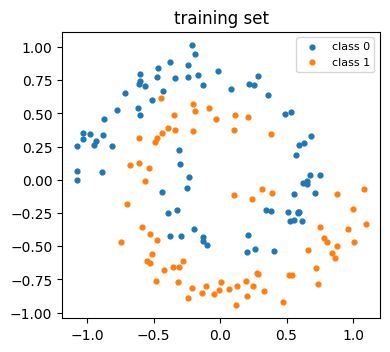

In [2]:
def make_spirals(n_per_class, noise, rng):
    # Two interleaved spirals, scaled to about [-1, 1]^2.
    t = np.sqrt(rng.uniform(0.05, 1.0, size=(2, n_per_class))) * 3 * np.pi
    points, labels = [], []
    for c in range(2):
        angle = t[c] + c * np.pi
        xy = np.stack([t[c] * np.cos(angle), t[c] * np.sin(angle)], axis=1) / (3 * np.pi)
        points.append(xy + noise * rng.normal(size=xy.shape))
        labels.append(np.full(n_per_class, c))
    X = np.concatenate(points).astype(np.float32)
    y = np.concatenate(labels)
    order = rng.permutation(len(y))
    return X[order], y[order]


rng = np.random.default_rng(0)
X, labels = make_spirals(275, noise=0.08, rng=rng)
Y = np.eye(2, dtype=np.float32)[labels]          # one-hot targets

X_train, Y_train = X[:150], Y[:150]
X_val, Y_val = X[150:350], Y[150:350]
X_test, Y_test = X[350:], Y[350:]
print('train / val / test:', len(X_train), len(X_val), len(X_test))

fig, ax = plt.subplots(figsize=(4, 4))
for c, color in enumerate(['tab:blue', 'tab:orange']):
    m = Y_train[:, 1] == c
    ax.scatter(*X_train[m].T, s=12, color=color, label=f'class {c}')
ax.set_aspect('equal'); ax.legend(fontsize=8, loc='upper right'); ax.set_title('training set')
plt.tight_layout()

`DataLoader` accepts a tuple of arrays directly (it wraps them in an `ArrayDataset`) and yields batches with the same structure, stacked along a new leading axis. `shuffle=True` with a `seed` reshuffles every epoch in a reproducible order.

In [3]:
train_loader = bt.DataLoader((X_train, Y_train), batch_size=25, shuffle=True, seed=0)
val_loader = bt.DataLoader((X_val, Y_val), batch_size=200)
test_loader = bt.DataLoader((X_test, Y_test), batch_size=200)

x_batch, y_batch = next(iter(train_loader))
print('batches per epoch:', len(train_loader), ' batch shapes:', x_batch.shape, y_batch.shape)

batches per epoch: 6  batch shapes: (25, 2) (25, 2)


## 2. The model

A `LightningModule` is a `brainstate.nn.Module`, so layers are declared as attributes as usual. On top of `__call__` it defines the steps the trainer calls:

- `training_step(batch, batch_idx)` returns a dict with the `'loss'` to differentiate. The trainer runs it inside `brainstate.transform.grad` and `jit`, so it must be traceable. `self.log(name, value)` records extra metrics; they are logged at every step.
- `validation_step` and `test_step` return a dict of metrics. The trainer averages them over the batches and adds a `val_` or `test_` prefix.
- `predict_step` returns anything; `Trainer.predict` collects the results.
- `configure_optimizers` returns a `braintools.optim` optimizer. Here it is SGD with momentum.

In [4]:
class SpiralClassifier(bt.LightningModule):
    def __init__(self, hidden=128, lr=0.02):
        super().__init__()
        self.lr = lr
        self.l1 = brainstate.nn.Linear(2, hidden)
        self.l2 = brainstate.nn.Linear(hidden, hidden)
        self.l3 = brainstate.nn.Linear(hidden, 2)

    def __call__(self, x):
        h = jnp.tanh(self.l1(x))
        h = jnp.tanh(self.l2(h))
        return self.l3(h)                      # logits

    def _loss_and_acc(self, batch):
        x, y = batch
        logits = self(x)
        loss = braintools.metric.softmax_cross_entropy(logits, y).mean()
        acc = jnp.mean(jnp.argmax(logits, -1) == jnp.argmax(y, -1))
        return loss, acc

    def training_step(self, batch, batch_idx):
        loss, acc = self._loss_and_acc(batch)
        self.log('loss', loss)
        self.log('acc', acc)
        return {'loss': loss}

    def validation_step(self, batch, batch_idx):
        loss, acc = self._loss_and_acc(batch)
        return {'loss': loss, 'acc': acc}

    def test_step(self, batch, batch_idx):
        loss, acc = self._loss_and_acc(batch)
        return {'loss': loss, 'acc': acc}

    def predict_step(self, batch, batch_idx):
        x, _ = batch
        return jnp.argmax(self(x), axis=-1)

    def configure_optimizers(self):
        return braintools.optim.SGD(lr=self.lr, momentum=0.9)

## 3. Training with callbacks and a CSV logger

Everything the run writes goes to a temporary directory:

- `ModelCheckpoint` saves a checkpoint after every validation whose `val_loss` is among the `save_top_k=2` best seen so far (older ones are deleted), and `last.ckpt` at the end of the run. The file name template can use `{epoch}` and any metric.
- `EarlyStopping` stops the run once `val_loss` has not improved by more than `min_delta` for `patience` epochs.
- `CSVLogger` writes every logged metric to `<save_dir>/<name>/<version>/metrics.csv`, and the trainer's hyperparameters to `hparams.yaml`.

`enable_progress_bar=False` keeps the output short. Checkpoints are saved only by a `ModelCheckpoint` callback; `enable_checkpointing` is kept for compatibility and has no effect. `default_root_dir` points the trainer's own files at the temporary directory too (by default it is the current working directory).

In [5]:
run_dir = tempfile.mkdtemp(prefix='braintools_trainer_')

checkpoint = bt.ModelCheckpoint(
    dirpath=os.path.join(run_dir, 'checkpoints'),
    filename='epoch{epoch:03d}-val{val_loss:.4f}',
    monitor='val_loss', mode='min', save_top_k=2,
)
early_stopping = bt.EarlyStopping(monitor='val_loss', mode='min', patience=30, min_delta=1e-4)
logger = bt.CSVLogger(run_dir, name='spirals', version='run0')

brainstate.random.seed(0)
model = SpiralClassifier()
trainer = bt.Trainer(
    max_epochs=400,
    callbacks=[checkpoint, early_stopping],
    logger=logger,
    enable_progress_bar=False,
    enable_checkpointing=False,
    default_root_dir=run_dir,
    seed=0,
)
trainer.fit(model, train_loader, val_loader)

print('stopped after epoch', trainer.current_epoch, f'({trainer.global_step} steps)')
print('final metrics:', {k: round(v, 4) for k, v in trainer.callback_metrics.items()})

stopped after epoch 319 (1920 steps)
final metrics: {'train_loss': 0.0494, 'train_acc': 0.98, 'val_loss': 0.2511, 'val_acc': 0.915}


`trainer.callback_metrics` holds the latest epoch averages. The callbacks keep their own state: the early-stopping epoch, and the best checkpoint with its score.

In [6]:
print('early stopping fired at epoch:', early_stopping.stopped_epoch)
print('best val_loss:', round(float(checkpoint.best_score), 4))
print('best checkpoint:', os.path.basename(checkpoint.best_model_path))
print('checkpoint dir:', sorted(os.listdir(checkpoint.dirpath)))
print('log dir:', sorted(os.listdir(logger.log_dir)))

early stopping fired at epoch: 319
best val_loss: 0.2189
best checkpoint: epoch289-val0.2189.ckpt
checkpoint dir: ['epoch280-val0.2226.ckpt', 'epoch289-val0.2189.ckpt', 'last.ckpt']
log dir: ['hparams.yaml', 'metrics.csv']


## 4. The logged curves

`metrics.csv` has one row per training step (columns `loss` and `acc`) and one row per validation run (columns `val_loss` and `val_acc`), indexed by the global step. Each validation row is written at the step count reached at the end of its epoch.

In [7]:
df = pd.read_csv(logger.metrics_file_path)
print(df.shape)
df.head(10)

(2240, 5)


,step,loss,acc,val_loss,val_acc
0,0,0.603733,0.68,NaN,NaN
1,1,0.628377,0.60,NaN,NaN
2,2,0.651708,0.60,NaN,NaN
3,3,0.628534,0.56,NaN,NaN
4,4,0.721221,0.56,NaN,NaN
5,5,0.670406,0.64,NaN,NaN
6,6,NaN,NaN,0.640779,0.645
7,6,0.603613,0.64,NaN,NaN
8,7,0.668528,0.60,NaN,NaN
9,8,0.597569,0.60,NaN,NaN


best epoch from the CSV: 289
train / val loss at the end: 0.0494 / 0.2511


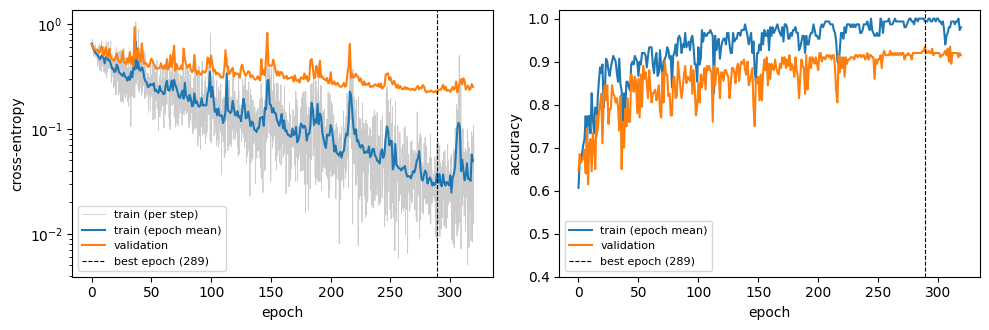

In [8]:
n_batches = len(train_loader)
train_rows = df.dropna(subset=['loss'])
val_rows = df.dropna(subset=['val_loss'])

# Average the per-step training metrics over each epoch.
train_epoch = train_rows.groupby(train_rows['step'] // n_batches)[['loss', 'acc']].mean()
val_epoch = val_rows['step'].to_numpy() // n_batches - 1
best_epoch = int(val_epoch[np.argmin(val_rows['val_loss'].to_numpy())])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(train_rows['step'] / n_batches, train_rows['loss'], color='0.8', lw=0.6, label='train (per step)')
axes[0].plot(train_epoch.index, train_epoch['loss'], label='train (epoch mean)')
axes[0].plot(val_epoch, val_rows['val_loss'], label='validation')
axes[0].set_yscale('log'); axes[0].set_ylabel('cross-entropy')
axes[1].plot(train_epoch.index, train_epoch['acc'], label='train (epoch mean)')
axes[1].plot(val_epoch, val_rows['val_acc'], label='validation')
axes[1].set_ylabel('accuracy'); axes[1].set_ylim(0.4, 1.02)
for ax in axes:
    ax.axvline(best_epoch, color='k', ls='--', lw=0.8, label=f'best epoch ({best_epoch})')
    ax.set_xlabel('epoch'); ax.legend(fontsize=8)
plt.tight_layout()

print('best epoch from the CSV:', best_epoch)
print('train / val loss at the end: %.4f / %.4f' % (train_epoch['loss'].iloc[-1], val_rows['val_loss'].iloc[-1]))

The training loss keeps falling (to 0.049 over the last epoch), while the validation loss levels off well above it from roughly epoch 200 on: with only 150 training points, the network starts fitting their noise. The lowest validation loss, 0.2189, came at epoch 289. No improvement larger than `min_delta` followed in the next 30 epochs (`patience=30`), so early stopping ended the run at epoch 319. Single steps are noisy (SGD with momentum on batches of 25 points), which is why the epoch means are drawn on top.

## 5. Reloading the best checkpoint

A checkpoint is a msgpack file holding the parameter values (`model_state_dict`), the optimizer state, the epoch, the metrics at save time and the callback states. `load_checkpoint` reads it as a dict:

In [9]:
ckpt = bt.load_checkpoint(checkpoint.best_model_path)
print(sorted(ckpt))
print('epoch:', ckpt['epoch'], ' metrics:', {k: round(float(v), 4) for k, v in ckpt['metrics'].items()})
print('parameters:', sorted(ckpt['model_state_dict']))

['callbacks', 'epoch', 'global_step', 'metrics', 'model_state_dict', 'optimizer_state_dict']
epoch: 289  metrics: {'val_acc': 0.935, 'val_loss': 0.2189}
parameters: ["('l1', 'weight')", "('l2', 'weight')", "('l3', 'weight')"]


To evaluate the best weights, build a fresh model with the same architecture and pass the checkpoint to `Trainer.test(..., ckpt_path=...)`, which loads it before running `test_step` on every batch. A separate `Trainer` with logging off is used for evaluation, so the training run's logs stay as they are. For comparison, the training trainer still holds the model as it was at the end of training:

In [10]:
final_metrics = trainer.test(dataloaders=test_loader, verbose=False)

evaluator = bt.Trainer(logger=False, enable_progress_bar=False, enable_checkpointing=False,
                       default_root_dir=run_dir)
best_model = SpiralClassifier()
best_metrics = evaluator.test(best_model, test_loader, ckpt_path=checkpoint.best_model_path, verbose=False)

print('final weights: test_loss = %.4f, test_acc = %.3f' % (final_metrics['test_loss'], final_metrics['test_acc']))
print('best weights:  test_loss = %.4f, test_acc = %.3f' % (best_metrics['test_loss'], best_metrics['test_acc']))

final weights: test_loss = 0.1624, test_acc = 0.960
best weights:  test_loss = 0.1390, test_acc = 0.965


On the 200 held-out test points, the best checkpoint does a little better than the final weights: a test loss of 0.139 against 0.162, and an accuracy of 0.965 against 0.960. The gap is small because the validation loss rose only slightly after its minimum, but the checkpoint was chosen on validation data alone, without looking at the test set.

`Trainer.predict` returns the output of `predict_step` for every batch. Below, both models classify a grid of points (a single batched call per model) and the test set:

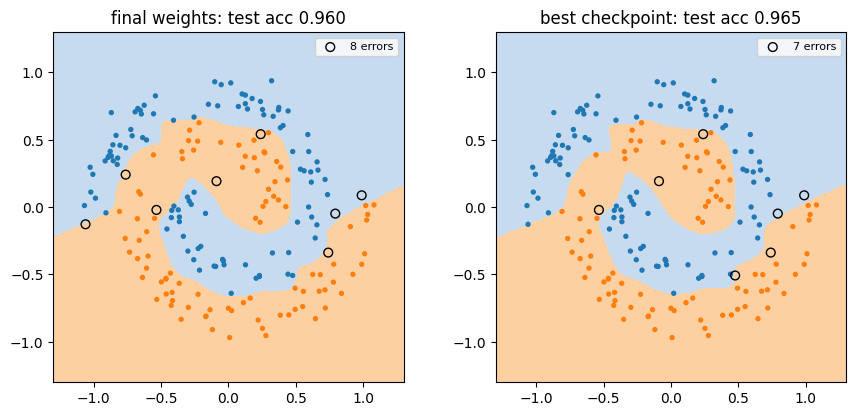

In [11]:
grid = np.linspace(-1.3, 1.3, 200, dtype=np.float32)
gx, gy = np.meshgrid(grid, grid)
grid_points = np.stack([gx.ravel(), gy.ravel()], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, (title, m, metrics) in zip(axes, [('final weights', model, final_metrics),
                                          ('best checkpoint', best_model, best_metrics)]):
    pred_test = np.concatenate(evaluator.predict(m, test_loader))
    region = np.asarray(jnp.argmax(m(grid_points), axis=-1)).reshape(gx.shape)
    ax.contourf(gx, gy, region, levels=[-0.5, 0.5, 1.5], colors=['#c6dbef', '#fdd0a2'])
    wrong = pred_test != Y_test.argmax(1)
    ax.scatter(*X_test[~wrong].T, s=8, c=np.where(Y_test[~wrong, 1] == 1, 'tab:orange', 'tab:blue'))
    ax.scatter(*X_test[wrong].T, s=40, facecolors='none', edgecolors='k', label=f'{wrong.sum()} errors')
    ax.set_title(f"{title}: test acc {metrics['test_acc']:.3f}")
    ax.set_aspect('equal'); ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()

Finally, remove the run directory:

In [12]:
shutil.rmtree(run_dir)
print(os.path.exists(run_dir))

False


## Summary

- A `LightningModule` defines `training_step` (traced under `jit` and `grad`, logs with `self.log`), `validation_step` / `test_step` (return metric dicts that the trainer averages and prefixes) and `configure_optimizers`.
- `DataLoader` batches plain arrays; give it a `seed` when shuffling.
- `ModelCheckpoint` keeps the `save_top_k` best checkpoints by a monitored metric plus `last.ckpt`; `EarlyStopping` ends the run when that metric stalls; `CSVLogger` writes a `metrics.csv` that pandas reads directly.
- `Trainer.test(model, loader, ckpt_path=...)` (and `validate` / `predict`) evaluates a fresh model from a saved checkpoint.

For anything beyond this loop (custom update rules, online learning, multi-optimizer schemes) drive the model directly with `brainstate.transform` and the `braintools.optim` optimizers; see the {doc}`optimization tutorials <../optim/index>`.